# Heart Disease Risk Prediction
## Model Explainability

In this notebook we try to understand what the selected model has learned, which features influence its predictions, and how we can explain individual predictions.

### Objectives
- 1. Global feature importance
Which features influence the model's predictions most across the dataset?
- 2. SHAP analysis
How do feature values contribute to predictions, and in which direction?
- 3. Individual prediction explanation
Why did the model produce a particular prediction for one patient record?

**Dataset:** UCI Heart Disease Dataset (Cleveland subset)

## 1. Imports and Configuration

In [1]:
import sys
import joblib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CURRENT_PATH = Path.cwd()

PROJECT_ROOT = next(
    (
        path for path in [CURRENT_PATH, *CURRENT_PATH.parents]
        if (path / "src").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.explain import (
    calculate_permutation_importance,
    get_transformed_feature_names,
    transform_features
)

sns.set_theme(style="whitegrid")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "heart_disease_model_input.csv"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "final_model.joblib"
)

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

print("Explainability environment initialized.")

Explainability environment initialized.


## 2. Load Dataset

In [2]:
df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["target"])
y = df["target"]

print("Dataset shape:", df.shape)

display(df.head())

print("\nTarget distribution:")
display(y.value_counts())

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Target distribution:


target
0    164
1    139
Name: count, dtype: int64

## 3. Load Final Model

In [4]:
final_model = joblib.load(MODEL_PATH)

print("Final model loaded successfully.")

print("\nModel architecture:")
print(final_model)

Final model loaded successfully.

Model architecture:
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                   

### 3.1 Load MetaData

In [5]:
import json

METADATA_PATH = (
    PROJECT_ROOT
    / "models"
    / "model_metadata.json"
)

with open(METADATA_PATH, "r") as file:
    metadata = json.load(file)

print("Selected model:", metadata["model_name"])
print("Training records:", metadata["training_records"])
print("CV ROC-AUC:", metadata["best_cv_roc_auc"])

Selected model: Logistic Regression
Training records: 303
CV ROC-AUC: 0.921021474667308


## 4. Verify Model and Dataset

In [6]:
assert list(X.columns) == metadata["feature_columns"]

sample_predictions = final_model.predict(X.head(5))

sample_probabilities = final_model.predict_proba(
    X.head(5)
)[:, 1]

print("Sample predictions:")
print(sample_predictions)

print("\nSample positive-class probabilities:")
print(sample_probabilities)

Sample predictions:
[0 1 1 0 0]

Sample positive-class probabilities:
[0.40959051 0.93660715 0.96541686 0.18880794 0.08152247]


## 5. Global Permutation Importance

In [7]:
importance_results = calculate_permutation_importance(
    model=final_model,
    X=X,
    y=y,
    n_repeats=30,
    random_state=42,
    scoring="roc_auc"
)

display(importance_results.round(4))

,Feature,Importance Mean,Importance Std
0,ca,0.0396,0.0066
1,cp,0.0298,0.0079
2,thal,0.0210,0.0055
3,sex,0.0130,0.0050
4,oldpeak,0.0110,0.0064
5,thalach,0.0062,0.0041
6,trestbps,0.0045,0.0028
7,slope,0.0036,0.0038
8,exang,0.0033,0.0039
9,restecg,0.0016,0.0020


### 5.1 Visualize the results

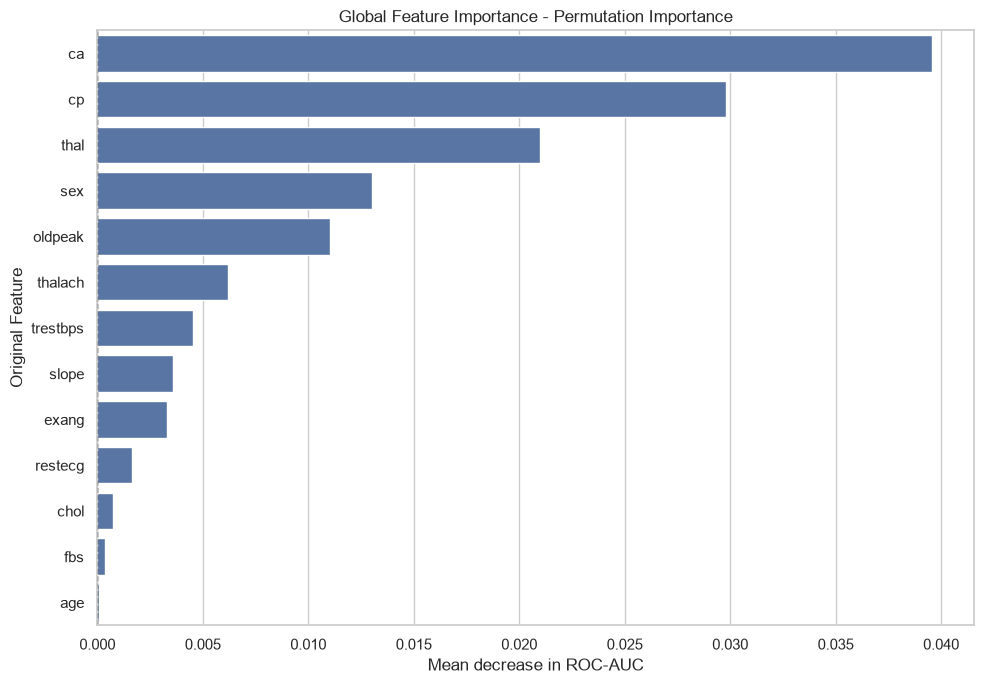

In [8]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_results,
    x="Importance Mean",
    y="Feature"
)

plt.axvline(
    0,
    linestyle="--",
    color="black",
    linewidth=1
)

plt.title(
    "Global Feature Importance - Permutation Importance"
)

plt.xlabel("Mean decrease in ROC-AUC")
plt.ylabel("Original Feature")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "permutation_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Save numerical results

In [9]:
importance_results.to_csv(
    REPORTS_DIR / "permutation_feature_importance.csv",
    index=False
)

## 6. SHAP Global Analysis

### 6.1 Prepare transformed features

In [11]:
import shap

X_transformed = transform_features(
    final_model,
    X
)

print("Original feature shape:", X.shape)
print("Transformed feature shape:", X_transformed.shape)

display(X_transformed.head())

Original feature shape: (303, 13)
Transformed feature shape: (303, 28)


,num__age,num__trestbps,num__chol,num__thalach,num__oldpeak,cat__sex_0.0,cat__sex_1.0,cat__cp_1.0,cat__cp_2.0,cat__cp_3.0,...,cat__slope_1.0,cat__slope_2.0,cat__slope_3.0,cat__ca_0.0,cat__ca_1.0,cat__ca_2.0,cat__ca_3.0,cat__thal_3.0,cat__thal_6.0,cat__thal_7.0
0,0.948726,0.757525,-0.264900,0.017197,1.087338,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.392002,1.611220,0.760415,-1.821905,0.397182,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2,1.392002,-0.665300,-0.342283,-0.902354,1.346147,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-1.932564,-0.096170,0.063974,1.637359,2.122573,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.489288,-0.096170,-0.825922,0.980537,0.310912,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


### 6.2 Create SHAP explainer

In [12]:
background = X_transformed.sample(
    n=min(30, len(X_transformed)),
    random_state=42
)

explanation_sample = X_transformed.sample(
    n=min(30, len(X_transformed)),
    random_state=21
)

classifier = final_model.named_steps["classifier"]

explainer = shap.PermutationExplainer(
    classifier.predict_proba,
    background
)

shap_values = explainer(
    explanation_sample,
    max_evals=2 * X_transformed.shape[1] + 1
)

print("SHAP explanation generated.")

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: Use

SHAP explanation generated.


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: Use

### 6.3 SHAP summary plot

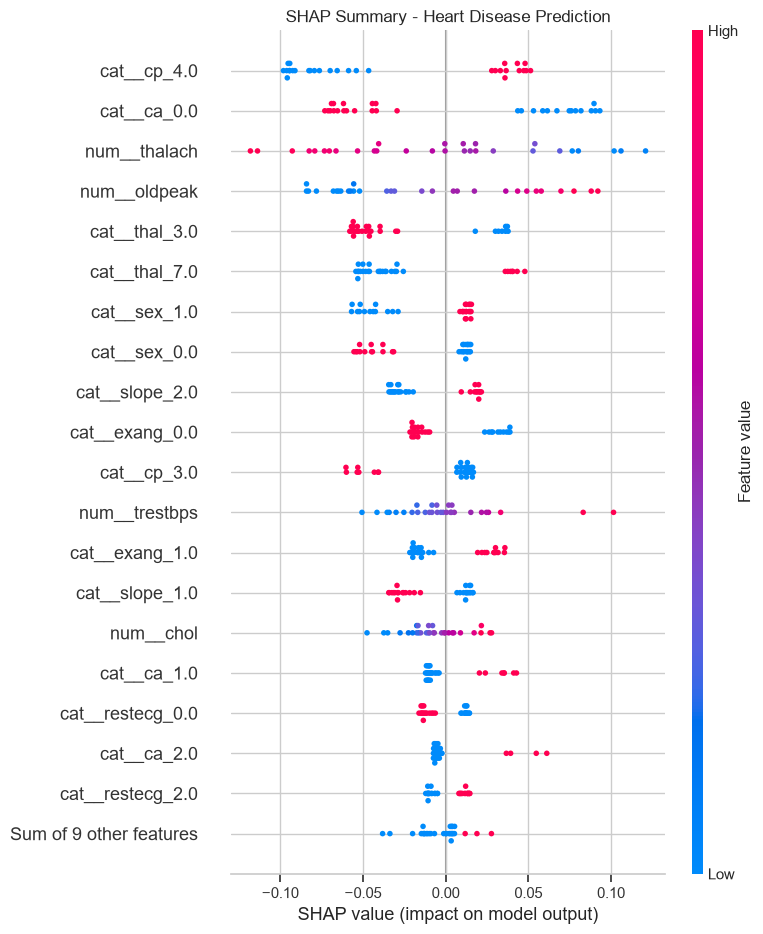

In [13]:
if shap_values.values.ndim == 3:
    positive_class_shap = shap_values[:, :, 1]
else:
    positive_class_shap = shap_values

shap.plots.beeswarm(
    positive_class_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary - Heart Disease Prediction")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.4 SHAP global importance

In [14]:
shap_importance = pd.DataFrame({
    "Feature": X_transformed.columns,
    "Mean Absolute SHAP": np.abs(
        positive_class_shap.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(shap_importance.head(20).round(4))

,Feature,Mean Absolute SHAP
10,cat__cp_4.0,0.0650
21,cat__ca_0.0,0.0642
3,num__thalach,0.0557
4,num__oldpeak,0.0530
25,cat__thal_3.0,0.0447
27,cat__thal_7.0,0.0423
6,cat__sex_1.0,0.0269
5,cat__sex_0.0,0.0266
19,cat__slope_2.0,0.0248
16,cat__exang_0.0,0.0228


### 6.5 Visualisation

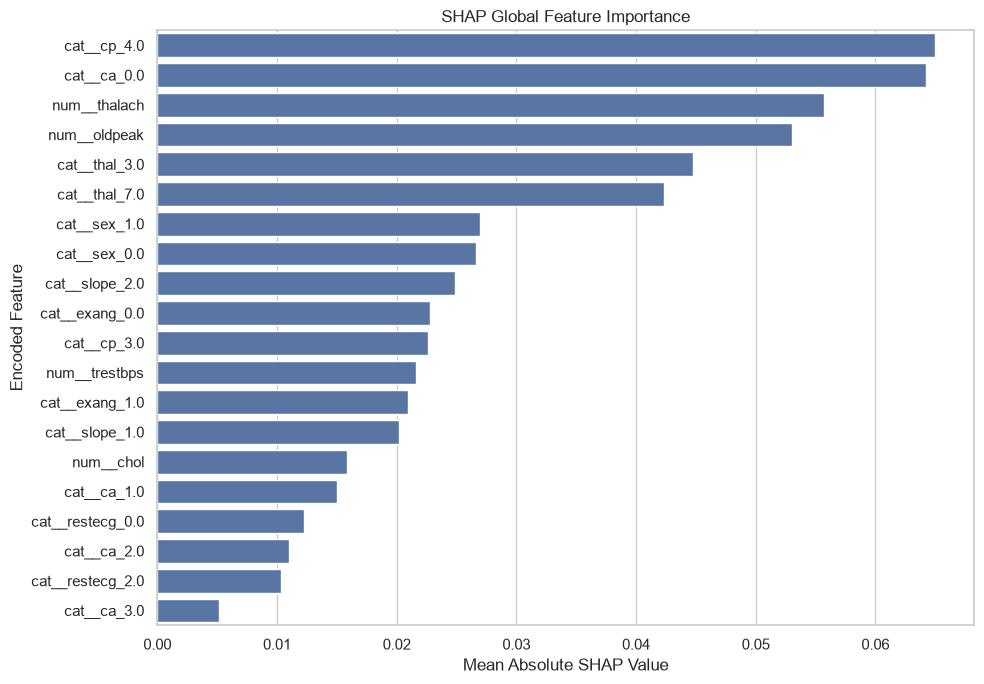

In [15]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=shap_importance.head(20),
    x="Mean Absolute SHAP",
    y="Feature"
)

plt.title("SHAP Global Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Encoded Feature")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

shap_importance.to_csv(
    REPORTS_DIR / "shap_global_importance.csv",
    index=False
)

## 7. Individual Prediction Explanation

### 7.1 Select an individual record

INDIVIDUAL PREDICTION
--------------------
Record index: 0
Actual class: 0
Predicted class: 0
Positive-class probability: 0.4096


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


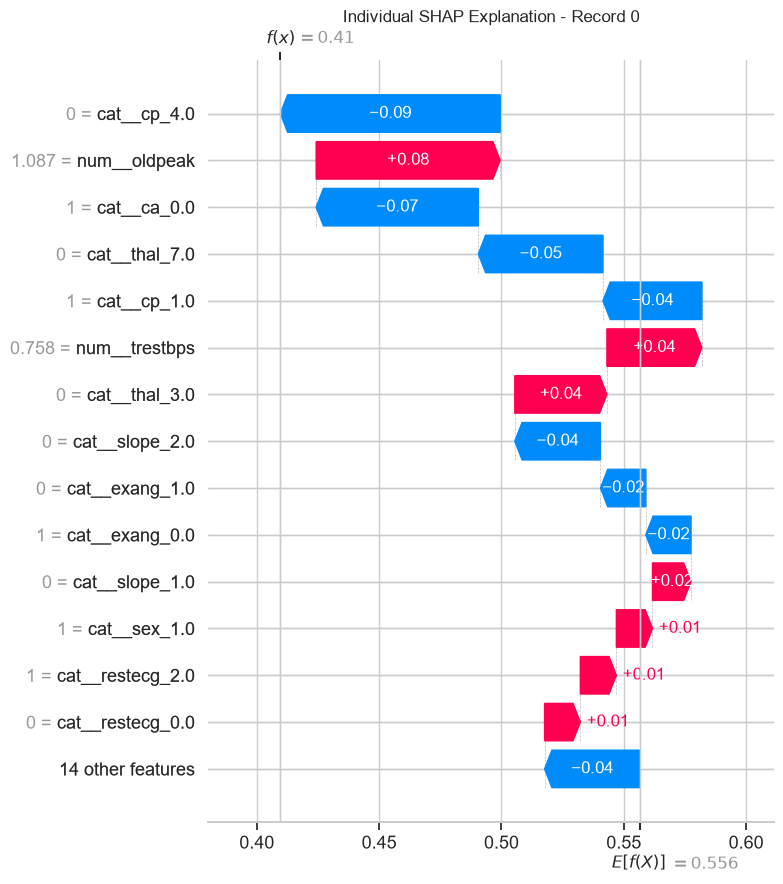

In [18]:

# ------------------------------------------------------------
# Individual prediction explanation
# ------------------------------------------------------------

sample_index = 0

# Select one original record
individual_record = X.iloc[[sample_index]]

actual_value = y.iloc[sample_index]

# Get prediction from complete pipeline
predicted_class = final_model.predict(
    individual_record
)[0]

predicted_probability = final_model.predict_proba(
    individual_record
)[0, 1]

print("INDIVIDUAL PREDICTION")
print("--------------------")
print("Record index:", sample_index)
print("Actual class:", actual_value)
print("Predicted class:", predicted_class)
print(
    "Positive-class probability:",
    round(predicted_probability, 4)
)

display(individual_record)

# Transform exactly this same record
individual_transformed = transform_features(
    final_model,
    individual_record
)

# Generate SHAP explanation for this exact record
individual_shap_values = explainer(
    individual_transformed,
    max_evals=2 * X_transformed.shape[1] + 1
)

# Select positive class explanation
if individual_shap_values.values.ndim == 3:
    individual_positive_shap = (
        individual_shap_values[:, :, 1]
    )
else:
    individual_positive_shap = individual_shap_values

# Generate waterfall plot
shap.plots.waterfall(
    individual_positive_shap[0],
    max_display=15,
    show=False
)

plt.title(
    "Individual SHAP Explanation - Record 0"
)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "individual_shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Feature,Mean Absolute Grouped SHAP
0,cp,0.0864
1,ca,0.0859
2,thal,0.0850
3,thalach,0.0557
4,sex,0.0536
5,oldpeak,0.0530
6,exang,0.0438
7,slope,0.0429
8,restecg,0.0226
9,trestbps,0.0216


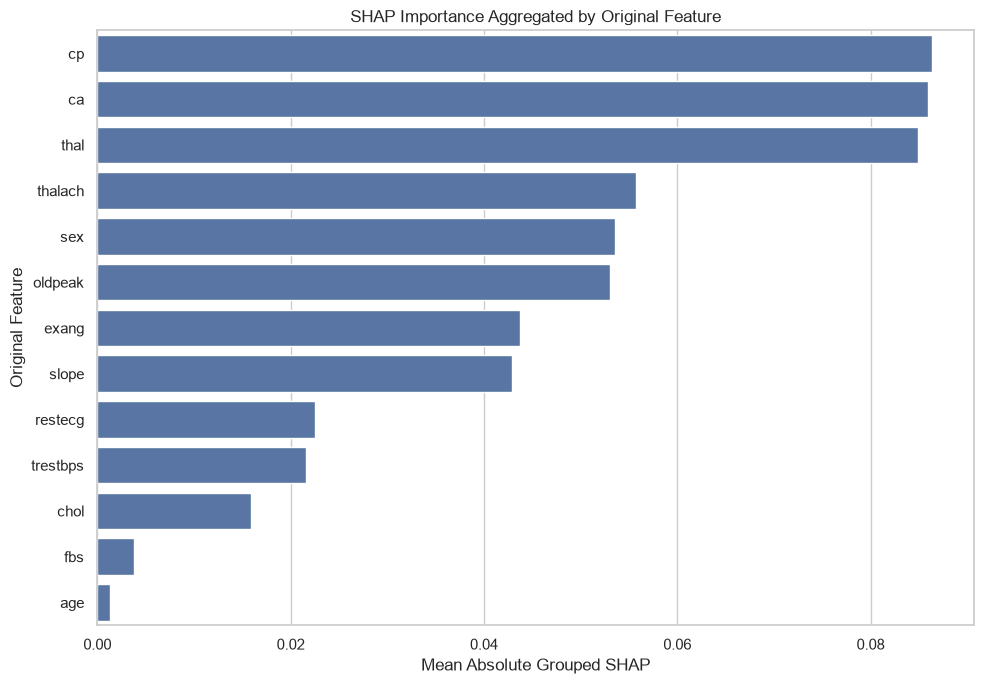

In [20]:

# ------------------------------------------------------------
# Aggregate SHAP values by original feature
# ------------------------------------------------------------

shap_matrix = positive_class_shap.values

original_features = X.columns.tolist()

grouped_shap = {}

for original_feature in original_features:

    matching_columns = [
        i for i, transformed_name in enumerate(
            X_transformed.columns
        )
        if (
            transformed_name == f"num__{original_feature}"
            or transformed_name.startswith(
                f"cat__{original_feature}_"
            )
        )
    ]

    if matching_columns:

        # Sum signed contributions across encoded columns
        feature_contribution = shap_matrix[
            :, matching_columns
        ].sum(axis=1)

        grouped_shap[original_feature] = np.abs(
            feature_contribution
        ).mean()

grouped_shap_df = pd.DataFrame({
    "Feature": list(grouped_shap.keys()),
    "Mean Absolute Grouped SHAP": list(
        grouped_shap.values()
    )
}).sort_values(
    "Mean Absolute Grouped SHAP",
    ascending=False
).reset_index(drop=True)

display(grouped_shap_df.round(4))

grouped_shap_df.to_csv(
    REPORTS_DIR / "shap_original_feature_importance.csv",
    index=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=grouped_shap_df,
    x="Mean Absolute Grouped SHAP",
    y="Feature"
)

plt.title(
    "SHAP Importance Aggregated by Original Feature"
)

plt.xlabel("Mean Absolute Grouped SHAP")
plt.ylabel("Original Feature")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "shap_original_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Explainability Findings and Conclusion

## Global Feature Importance

Permutation importance was used to investigate the
importance of the original input features.

SHAP analysis was additionally performed to examine
the contribution of transformed features to model outputs.

## Individual Prediction Explanation

SHAP waterfall plots were used to investigate how
individual feature contributions influenced a model
prediction relative to the selected background data.

## Interpretation

The explainability results describe the behaviour of
the trained machine learning model.

They do not establish causal relationships between
individual health measurements and heart disease.

## Limitations

- The dataset contains only 303 records.
- The model is trained on the Cleveland dataset.
- Correlated features can affect importance rankings.
- One-hot encoding produces multiple SHAP values
  for some original categorical variables.
- Explainability results depend on the selected model
  and background dataset.
- These explanations are not clinical evidence.

## Conclusion

Global and individual explainability techniques were
implemented to improve the transparency of the
experimental heart disease prediction model.

Further validation using independent datasets is
required before considering clinical applications.